In [3]:
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

@dataclass
class Population:
    """
    Diploid population.
    hap_counts has shape (N, 2):
        hap_counts[i, 0] = copy number of haplotype 1 in individual i
        hap_counts[i, 1] = copy number of haplotype 2 in individual i
    """
    hap_counts: np.ndarray

def initialize_population(N, mode="constant", rng=None, **kwargs):
    """
    Initialize a population under different starting distributions.

    Parameters
    ----------
    N : int
        Population size.
    mode : str
        One of {"constant", "gaussian", "poisson"}.
    rng : np.random.Generator
        Random number generator.
    kwargs :
        For constant: init_copies
        For gaussian: mean, sd
        For poisson: lam
    """
    if rng is None:
        rng = np.random.default_rng()

    if N <= 0:
        raise ValueError("N must be positive.")

    if mode == "constant":
        init_copies = kwargs.get("init_copies", 5)
        hap_counts = np.full((N, 2), init_copies, dtype=int)

    elif mode == "gaussian":
        mean = kwargs.get("mean", 10)
        sd = kwargs.get("sd", 2)
        hap_counts = rng.normal(loc=mean, scale=sd, size=(N, 2))
        hap_counts = np.round(hap_counts).astype(int)
        hap_counts[hap_counts < 1] = 1

    elif mode == "poisson":
        lam = kwargs.get("lam", 10)
        hap_counts = rng.poisson(lam=lam, size=(N, 2))
        hap_counts[hap_counts < 1] = 1

    else:
        raise ValueError(f"Unknown mode: {mode}")

    return Population(hap_counts=hap_counts)


def make_gamete(n1: int, n2: int, rec: float, rng: np.random.Generator) -> int:
    """
    Produce one gamete from a diploid parent carrying haplotypes
    with copy numbers n1 and n2.

    With probability 1-rec:
        inherit one haplotype unchanged.

    With probability rec:
        perform Otto-style recombination:
            choose breakpoints b1 in {1,...,n1}, b2 in {1,...,n2}
            then form either:
                b1 + (n2 - b2)
            or:
                b2 + (n1 - b1)

    Returns
    -------
    int
        Copy number in the gamete.
    """
    if n1 <= 0 or n2 <= 0:
        raise ValueError("Copy numbers must be positive integers.")
    if not (0.0 <= rec <= 1.0):
        raise ValueError("rec must be between 0 and 1.")

    # No recombination
    if rng.random() > rec:
        return n1 if rng.random() < 0.5 else n2

    # Recombination
    if rng.random() < 0.5:
        b1 = rng.integers(1, n1 + 1)  # inclusive of n1
        b2 = rng.integers(1, n2 + 1)  # inclusive of n2
        g = b1 + (n2 - b2)
    else:
        b2 = rng.integers(1, n2 + 1)
        b1 = rng.integers(1, n1 + 1)
        g = b2 + (n1 - b1)

    # In this model, gamete copy number should remain >= 1
    # because b1 and b2 are at least 1.
    if g <= 0:
        raise RuntimeError(f"Generated non-positive gamete copy number: {g}")

    return int(g)


def make_offspring(
    parent1: np.ndarray,
    parent2: np.ndarray,
    rec: float,
    rng: np.random.Generator
) -> np.ndarray:
    """
    Create one diploid offspring from two diploid parents.

    Each parent contributes one gamete.
    """
    if parent1.shape != (2,) or parent2.shape != (2,):
        raise ValueError("Each parent must be a length-2 array of haplotype copy numbers.")

    g1 = make_gamete(int(parent1[0]), int(parent1[1]), rec, rng)
    g2 = make_gamete(int(parent2[0]), int(parent2[1]), rec, rng)

    return np.array([g1, g2], dtype=int)


def evolve_one_generation(
    pop: Population,
    rec: float,
    rng: np.random.Generator | None = None
) -> Population:
    """
    Evolve the population by one generation under neutral
    Wright-Fisher sampling.

    For each offspring:
        - sample two parents uniformly from the current population
        - produce one gamete from each
        - combine them into a diploid offspring
    """
    if rng is None:
        rng = np.random.default_rng()

    hap = pop.hap_counts
    if hap.ndim != 2 or hap.shape[1] != 2:
        raise ValueError("hap_counts must have shape (N, 2).")

    N = hap.shape[0]
    if N == 0:
        raise ValueError("Population size must be positive.")

    new_counts = np.zeros_like(hap)

    for i in range(N):
        p1 = rng.integers(0, N)
        p2 = rng.integers(0, N)

        parent1 = hap[p1]
        parent2 = hap[p2]

        new_counts[i] = make_offspring(parent1, parent2, rec, rng)

    return Population(hap_counts=new_counts)


def describe_population(pop: Population) -> dict:
    """
    Return simple summary statistics for the population.
    """
    hap = pop.hap_counts
    dip = hap.sum(axis=1)

    stats = {
        "N": int(hap.shape[0]),
        "mean_hap": float(hap.mean()),
        "var_hap": float(hap.var(ddof=1)) if hap.size > 1 else 0.0,
        "min_hap": int(hap.min()),
        "max_hap": int(hap.max()),
        "mean_dip": float(dip.mean()),
        "var_dip": float(dip.var(ddof=1)) if len(dip) > 1 else 0.0,
        "min_dip": int(dip.min()),
        "max_dip": int(dip.max()),
    }
    return stats


def simulate(
    N: int,
    init_copies: int,
    rec: float,
    generations: int,
    seed: int | None = None,
    record_every: int = 1,
    mode: str = "constant",
    init_sd: float = 2.0,
):
    """
    Run one simulation and record summary statistics over time.
    """
    if generations < 0:
        raise ValueError("generations must be >= 0.")
    if record_every <= 0:
        raise ValueError("record_every must be positive.")

    rng = np.random.default_rng(seed)

    if mode == "constant":
        pop = initialize_population(
            N=N,
            mode=mode,
            rng=rng,
            init_copies=init_copies
        )
    elif mode == "gaussian":
        pop = initialize_population(
            N=N,
            mode=mode,
            rng=rng,
            mean=init_copies,
            sd=init_sd
        )
    elif mode == "poisson":
        pop = initialize_population(
            N=N,
            mode=mode,
            rng=rng,
            lam=init_copies
        )
    else:
        raise ValueError(f"Unknown mode: {mode}")

    history = [{"generation": 0, **describe_population(pop)}]

    for gen in range(1, generations + 1):
        pop = evolve_one_generation(pop, rec=rec, rng=rng)

        if gen % record_every == 0:
            history.append({"generation": gen, **describe_population(pop)})

    return pop, history


def print_history(history: list[dict]) -> None:
    """
    print the recorded summary statistics.
    """
    header = (
        f"{'gen':>6}  {'mean_hap':>10}  {'var_hap':>10}  "
        f"{'min_hap':>8}  {'max_hap':>8}  {'mean_dip':>10}  {'var_dip':>10}"
    )
    print(header)
    print("-" * len(header))

    for row in history:
        print(
            f"{row['generation']:6d}  "
            f"{row['mean_hap']:10.4f}  "
            f"{row['var_hap']:10.4f}  "
            f"{row['min_hap']:8d}  "
            f"{row['max_hap']:8d}  "
            f"{row['mean_dip']:10.4f}  "
            f"{row['var_dip']:10.4f}"
        )

def plot_final_distributions(pop: Population) -> None:
    """
    Plot final haplotype and diploid copy-number distributions.
    """
    hap = pop.hap_counts.flatten()
    dip = pop.hap_counts.sum(axis=1)

    hap_bins = np.arange(hap.min(), hap.max() + 2) - 0.5
    dip_bins = np.arange(dip.min(), dip.max() + 2) - 0.5

    plt.figure(figsize=(7, 5))
    plt.hist(hap, bins=hap_bins, edgecolor="black")
    plt.xlabel("Haplotype copy number")
    plt.ylabel("Frequency")
    plt.title("Final haplotype copy number distribution")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.hist(dip, bins=dip_bins, edgecolor="black")
    plt.xlabel("Diploid total copy number")
    plt.ylabel("Frequency")
    plt.title("Final diploid copy number distribution")
    plt.tight_layout()
    plt.show()


In [4]:
def run_parameter_grid(
    Ns,
    recs,
    replicates,
    generations,
    init_copies=10,
    mode="gaussian",
    init_sd=2.0,
    seed_base=12345,
):
    """
    Run many replicates across combinations of N and rec.

    Returns
    -------
    df : pandas.DataFrame
        One row per replicate, containing final summary statistics.
    """
    results = []

    for N in Ns:
        for rec in recs:
            print(f"\nRunning N={N}, rec={rec} ...")

            for rep in range(replicates):
                seed = seed_base + rep + 1000 * int(rec * 1000) + 100000 * (N // 1000)

                pop, history = simulate(
                    N=N,
                    init_copies=init_copies,
                    rec=rec,
                    generations=generations,
                    seed=seed,
                    record_every=generations,
                    mode=mode,
                    init_sd=init_sd,
                )

                stats = describe_population(pop)

                results.append({
                    "N": N,
                    "rec": rec,
                    "replicate": rep,
                    "mode": mode,
                    "generations": generations,
                    "init_copies": init_copies,
                    "mean_hap": stats["mean_hap"],
                    "var_hap": stats["var_hap"],
                    "min_hap": stats["min_hap"],
                    "max_hap": stats["max_hap"],
                    "mean_dip": stats["mean_dip"],
                    "var_dip": stats["var_dip"],
                    "min_dip": stats["min_dip"],
                    "max_dip": stats["max_dip"],
                })

            print(f"Finished N={N}, rec={rec}")

    df = pd.DataFrame(results)
    return df
def summarize_results(df: pd.DataFrame) -> pd.DataFrame:
    """
    Summarize replicate results by parameter combination.
    """
    summary = (
        df.groupby(["N", "rec"])[["mean_hap", "var_hap", "mean_dip", "var_dip"]]
        .agg(["mean", "std"])
        .round(4)
    )
    return summary


def plot_box_by_group(df: pd.DataFrame, column: str) -> None:
    """
    Boxplot for a summary statistic across parameter combinations.
    """
    groups = []
    labels = []

    for N in sorted(df["N"].unique()):
        for rec in sorted(df["rec"].unique()):
            subset = df[(df["N"] == N) & (df["rec"] == rec)][column]
            groups.append(subset.values)
            labels.append(f"N={N}\nr={rec}")

    plt.figure(figsize=(8, 5))
    plt.boxplot(groups, tick_labels=labels)
    plt.ylabel(column)
    plt.title(f"Final {column} across parameter combinations")
    plt.tight_layout()
    plt.show()



Single-run history:

   gen    mean_hap     var_hap   min_hap   max_hap    mean_dip     var_dip
--------------------------------------------------------------------------
     0      9.8920      4.1204         3        16     19.7840      8.7581
    50      8.0655     19.8421         1        27     16.1310     39.4973
   100      7.1405     19.6346         1        29     14.2810     37.7518
   150      8.1115     31.3387         1        30     16.2230     63.9012
   200      8.2185     40.0598         1        36     16.4370     78.0180
   250      8.9390     45.4310         1        38     17.8780     90.8780
   300      9.7950     43.1996         1        39     19.5900     92.8968
   350      9.6735     49.5587         1        37     19.3470    100.4831
   400      9.3240     42.7414         1        38     18.6480     80.1102
   450      8.9585     34.3259         1        31     17.9170     67.7779
   500      9.8650     47.9658         1        43     19.7300     95.6528

Fin

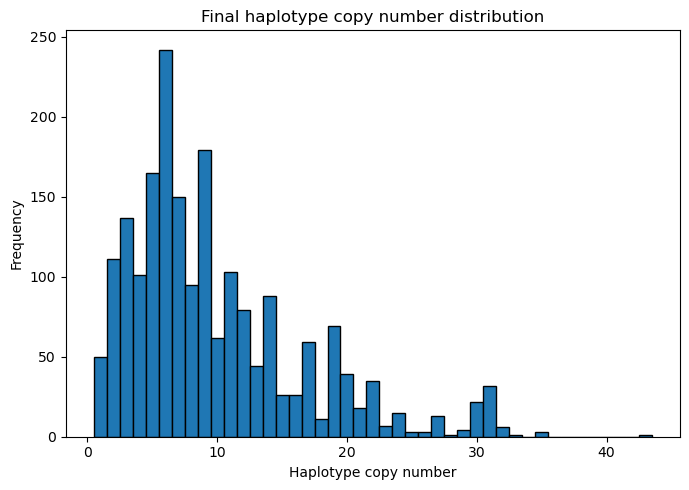

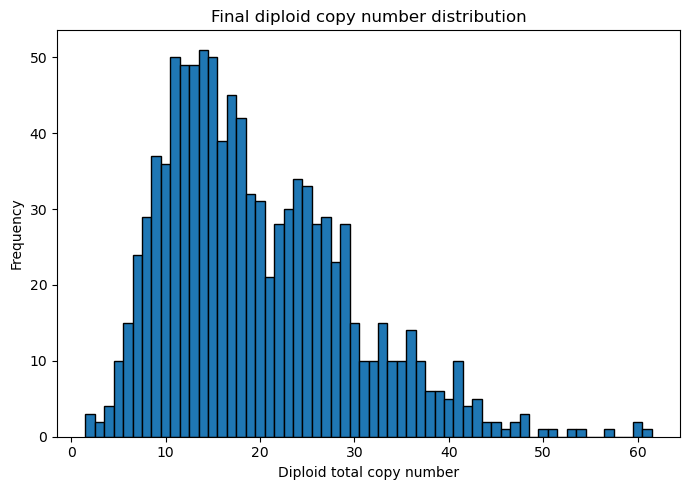


Running N=1000, rec=0.01 ...
Finished N=1000, rec=0.01

Running N=1000, rec=0.05 ...
Finished N=1000, rec=0.05

Running N=5000, rec=0.01 ...
Finished N=5000, rec=0.01

Running N=5000, rec=0.05 ...
Finished N=5000, rec=0.05

Replicate results (first 10 rows):
      N   rec  replicate      mode  generations  init_copies  mean_hap  \
0  1000  0.01          0  gaussian        10000           10   31.8555   
1  1000  0.01          1  gaussian        10000           10   25.3905   
2  1000  0.01          2  gaussian        10000           10    1.9195   
3  1000  0.01          3  gaussian        10000           10    4.2760   
4  1000  0.01          4  gaussian        10000           10   93.6845   
5  1000  0.01          5  gaussian        10000           10    5.4335   
6  1000  0.01          6  gaussian        10000           10    3.4095   
7  1000  0.01          7  gaussian        10000           10    1.0000   
8  1000  0.01          8  gaussian        10000           10    3.2050   


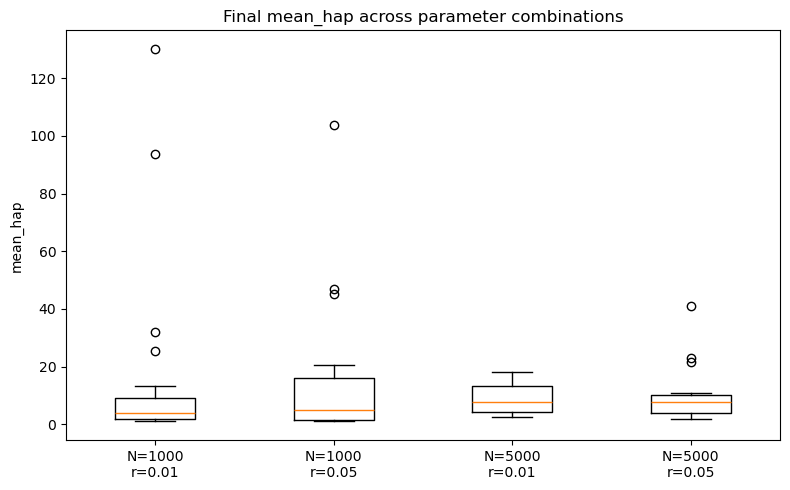

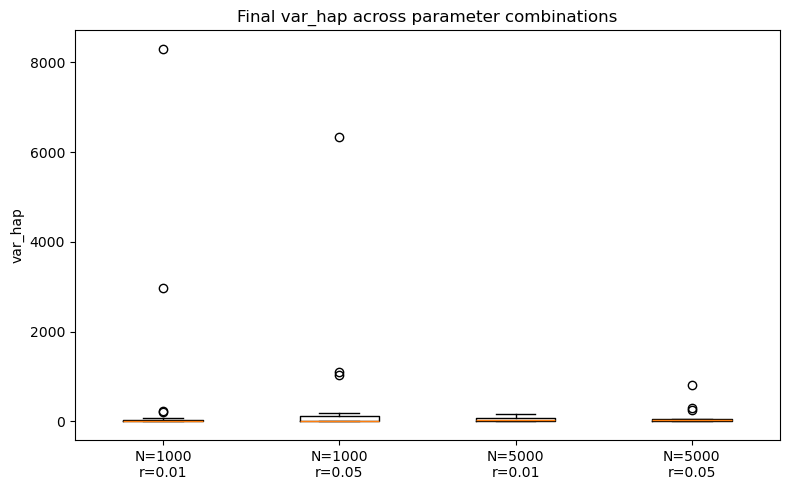

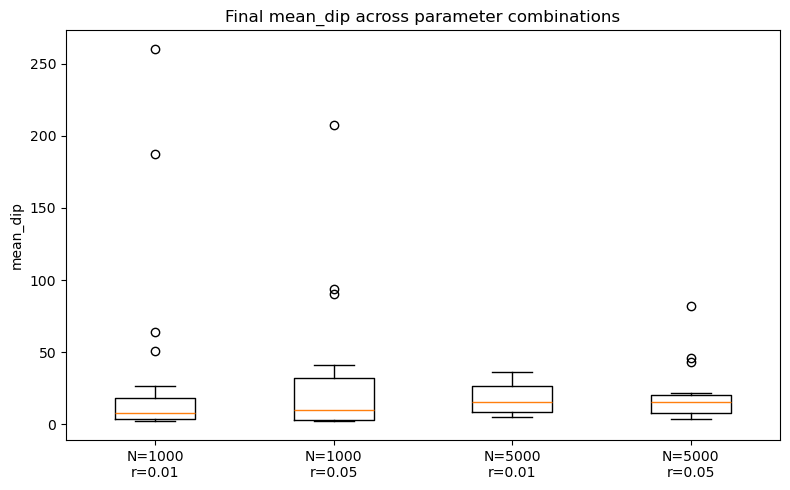

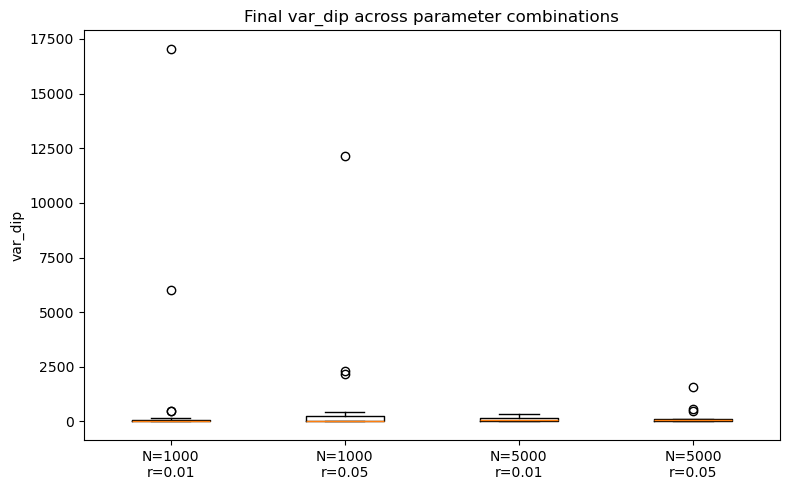


Saved replicate results to neutral_cnv_replicates_results.csv


In [5]:
def main():
    # --------------------------
    # Single-run example
    # --------------------------
    N = 1000
    init_copies = 10
    rec = 0.05
    generations = 500
    seed = 42
    record_every = 50
    mode = "gaussian"

    pop, history = simulate(
        N=N,
        init_copies=init_copies,
        rec=rec,
        generations=generations,
        seed=seed,
        record_every=record_every,
        mode=mode,
        init_sd=2.0,
    )

    print("Single-run history:\n")
    print_history(history)

    print("\nFinal population (first 10 individuals):")
    print(pop.hap_counts[:10])

    plot_final_distributions(pop)

    # --------------------------
    # Replicate grid
    # --------------------------
    Ns = [1000, 5000]
    recs = [0.01, 0.05]
    replicates = 20   # first test with 20
    generations_grid = 10000

    df = run_parameter_grid(
        Ns=Ns,
        recs=recs,
        replicates=replicates,
        generations=generations_grid,
        init_copies=10,
        mode="gaussian",
        init_sd=2.0,
        seed_base=12345,
    )

    print("\nReplicate results (first 10 rows):")
    print(df.head(10))

    print("\nSummary by parameter combination:")
    print(summarize_results(df))

    plot_box_by_group(df, "mean_hap")
    plot_box_by_group(df, "var_hap")
    plot_box_by_group(df, "mean_dip")
    plot_box_by_group(df, "var_dip")

    # optional: save results
    df.to_csv("neutral_cnv_replicates_results.csv", index=False)
    print("\nSaved replicate results to neutral_cnv_replicates_results.csv")


if __name__ == "__main__":
    main()

In [6]:
df = pd.read_csv("neutral_cnv_replicates_results.csv")
print(df.head())

      N   rec  replicate      mode  generations  init_copies  mean_hap  \
0  1000  0.01          0  gaussian        10000           10   31.8555   
1  1000  0.01          1  gaussian        10000           10   25.3905   
2  1000  0.01          2  gaussian        10000           10    1.9195   
3  1000  0.01          3  gaussian        10000           10    4.2760   
4  1000  0.01          4  gaussian        10000           10   93.6845   

       var_hap  min_hap  max_hap  mean_dip      var_dip  min_dip  max_dip  
0   235.697468        2      104    63.711   477.054534        7      142  
1   221.044532        3       73    50.781   463.002041        9      121  
2     0.829434        1        5     3.839     1.704784        2        8  
3     8.252950        1       15     8.552    16.986282        2       23  
4  2984.333126       15      267   187.369  6027.454293       39      481  


In [7]:
def plot_mean_box(df, column="mean_hap", save_path=None):
    import matplotlib.pyplot as plt

    groups = []
    labels = []

    for N in sorted(df["N"].unique()):
        for rec in sorted(df["rec"].unique()):
            subset = df[(df["N"] == N) & (df["rec"] == rec)][column]
            groups.append(subset.values)
            labels.append(f"N={N}\nr={rec}")

    plt.figure(figsize=(8, 5))
    plt.boxplot(groups, tick_labels=labels)
    plt.ylabel(column)
    plt.title(f"{column} across replicates")
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300)

    plt.show()

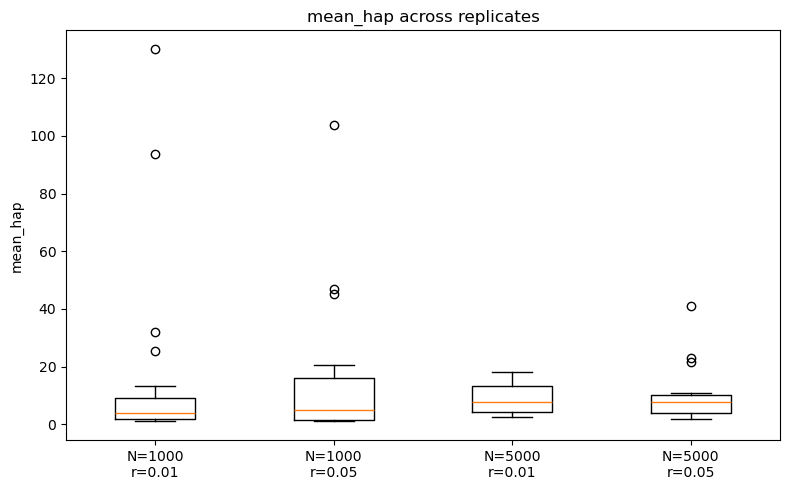

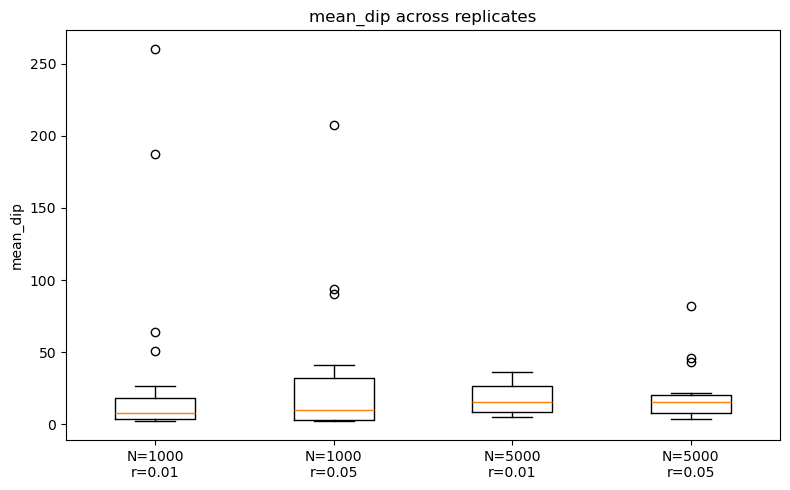

In [8]:
plot_mean_box(df, "mean_hap", save_path="mean_hap_boxplot.pdf")
plot_mean_box(df, "mean_dip", save_path="mean_dip_boxplot.pdf")

In [9]:
def validate_v1(
    N=20,
    rec_values=(0.0, 0.001, 0.01, 0.05, 0.1),
    replicates=1000,
    max_generations=5000,
    initial_copies=10,
):
    rng = np.random.default_rng(seed)
    results = []

    mutant_copies = initial_copies + 1

    for rec in rec_values:

        first_fix_times = []
        first_loss_times = []
        fixed = 0
        lost = 0
        censored = 0
        escaped_after_fixation = 0

        for rep in range(replicates):

            # Start with a monomorphic population
            pop = initialize_population(
                N=N,
                mode="constant",
                init_copies=initial_copies
            )

            # Introduce one 11-copy haplotype
            pop.hap_counts[0, 0] = mutant_copies

            for t in range(1, max_generations + 1):

                pop = evolve_one_generation(
                    pop, rec=rec, rng=rng
                )

                mutant_count = np.count_nonzero(
                    pop.hap_counts == mutant_copies
                )

                # First arrival at zero frequency
                if mutant_count == 0:
                    lost += 1
                    first_loss_times.append(t)
                    break

                # First arrival at 100% frequency
                if mutant_count == 2 * N:
                    fixed += 1
                    first_fix_times.append(t)

                    # Is the monomorphic state stable
                    # for one more generation?
                    next_pop = evolve_one_generation(
                        pop, rec=rec, rng=rng
                    )

                    if not np.all(
                        next_pop.hap_counts == mutant_copies
                    ):
                        escaped_after_fixation += 1

                    break

            else:
                censored += 1

        results.append({
            "N": N,
            "rec": rec,
            "P_first_fix": fixed / replicates,
            "P_first_loss": lost / replicates,
            "P_censored": censored / replicates,
            "T_first_fix": (
                np.mean(first_fix_times)
                if first_fix_times else np.nan
            ),
            "T_first_loss": (
                np.mean(first_loss_times)
                if first_loss_times else np.nan
            ),
            "P_escape_after_fix": (
                escaped_after_fixation / fixed
                if fixed else np.nan
            ),
            "n_fixed": fixed
        })

    return pd.DataFrame(results)

In [14]:
N_values = [10, 20, 50, 100, 200]
results = []

for N in N_values:
    df = validate_v1(
        N=N,
        rec_values=[0.0],
        replicates=10000,
        max_generations=20 * N,
    )

    results.append(df)

df_N = pd.concat(results, ignore_index=True)

df_N["P_fix_theory"] = 1 / (2 * df_N["N"])
df_N["T_fix_theory"] = 4 * df_N["N"]

print(df_N.round(4))

     N  rec  P_first_fix  P_first_loss  P_censored  T_first_fix  T_first_loss  \
0   10  0.0       0.0493        0.9507         0.0      36.4097        5.6518   
1   20  0.0       0.0260        0.9740         0.0      75.0308        7.0020   
2   50  0.0       0.0089        0.9911         0.0     209.5955        8.6790   
3  100  0.0       0.0054        0.9946         0.0     386.8148       10.3847   
4  200  0.0       0.0031        0.9969         0.0     946.1290       12.0925   

   P_escape_after_fix  n_fixed  P_fix_theory  T_fix_theory  
0                 0.0      493        0.0500            40  
1                 0.0      260        0.0250            80  
2                 0.0       89        0.0100           200  
3                 0.0       54        0.0050           400  
4                 0.0       31        0.0025           800  


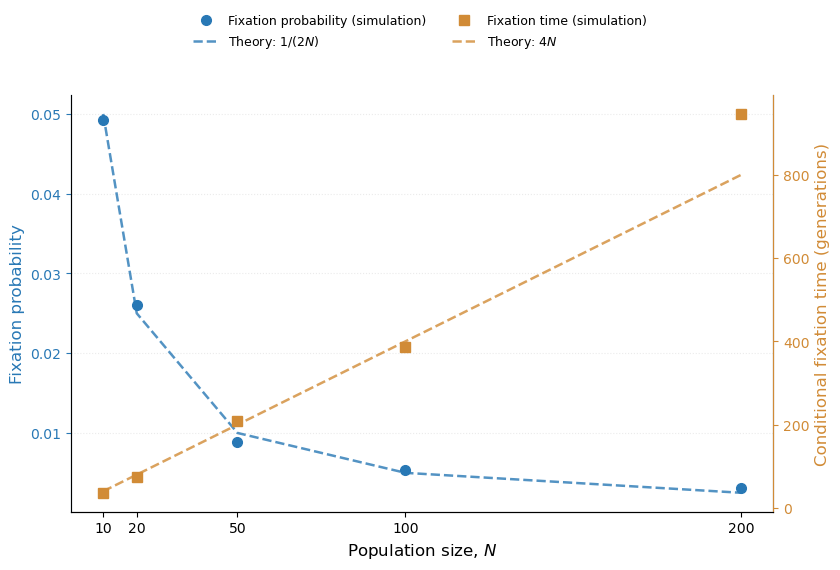

In [42]:
# Sort by population size
df = df_N.sort_values("N")

fig, ax1 = plt.subplots(figsize=(8.5, 5.5))
ax2 = ax1.twinx()

# Colors
c_prob = "#2878B5"   # Blue
c_time = "#D18B36"   # Orange

# --- Fixation probability (left axis) ---
ax1.plot(
    df["N"], df["P_first_fix"],
    "o", color=c_prob, markersize=7,
    label="Fixation probability (simulation)",
    zorder=5
)

ax1.plot(
    df["N"], 1 / (2 * df["N"]),
    "--", color=c_prob, linewidth=1.8,
    alpha=0.8,
    label=r"Theory: $1/(2N)$"
)

# --- Fixation time (right axis) ---
ax2.plot(
    df["N"], df["T_first_fix"],
    "s", color=c_time, markersize=7,
    label="Fixation time (simulation)",
    zorder=5
)

ax2.plot(
    df["N"], 4 * df["N"],
    "--", color=c_time, linewidth=1.8,
    alpha=0.8,
    label=r"Theory: $4N$"
)

# --- Axes ---
ax1.set_xlabel("Population size, $N$", fontsize=12)
ax1.set_ylabel(
    "Fixation probability",
    fontsize=12,
    color=c_prob
)
ax2.set_ylabel(
    "Conditional fixation time (generations)",
    fontsize=12,
    color=c_time
)

ax1.tick_params(axis="y", colors=c_prob)
ax2.tick_params(axis="y", colors=c_time)

ax1.set_xticks(df["N"])

# Subtle grid
ax1.grid(
    axis="y",
    linestyle=":",
    alpha=0.25
)

# Remove unnecessary borders
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

ax1.spines["left"].set_color(c_prob)
ax2.spines["right"].set_color(c_time)

# --- Combined legend ---
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

fig.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=2,
    frameon=False,
    fontsize=9
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

In [16]:
# V0.3 — Otto equilibrium validation

from scipy.stats import gamma

def evolve_fast(pop, rec, rng):
    """
    Vectorized version of evolve_one_generation().
    Same reproductive sampling and recombination rules.
    """
    hap = pop.hap_counts
    N = len(hap)
    M = 2 * N

    # Sample a parent for each gamete
    parents = rng.integers(0, N, size=M)
    n1 = hap[parents, 0]
    n2 = hap[parents, 1]

    # Ordinary inheritance
    gametes = np.where(
        rng.random(M) < 0.5, n1, n2
    ).copy()

    # Recombination
    mask = rng.random(M) < rec
    k = np.sum(mask)

    if k > 0:
        a = n1[mask]
        b = n2[mask]

        b1 = rng.integers(1, a + 1)
        b2 = rng.integers(1, b + 1)

        gametes[mask] = np.where(
            rng.random(k) < 0.5,
            b1 + b - b2,
            b2 + a - b1
        )

    return Population(gametes.reshape(N, 2))

In [35]:
# Parameters
N = 10000
rec = 0.1
generations = 2000
init_copies = 10
record_every = 20

rng = np.random.default_rng(42)

pop = initialize_population(
    N=N,
    mode="constant",
    init_copies=init_copies,
    rng=rng
)

history = []

for t in range(generations + 1):

    if t % record_every == 0:
        stats = describe_population(pop)

        mean = stats["mean_dip"]
        var = stats["var_dip"]

        history.append({
            "generation": t,
            "mean_dip": mean,
            "var_dip": var,
            "alpha_est": mean**2 / var if var > 0 else np.nan
        })

    if t < generations:
        pop = evolve_fast(pop, rec, rng)

df_history = pd.DataFrame(history)
dip = pop.hap_counts.sum(axis=1)

print(df_history.tail())

     generation  mean_dip     var_dip  alpha_est
96         1920   21.2972  105.676640   4.292062
97         1940   20.8692  109.059997   3.993430
98         1960   20.9251  109.993889   3.980765
99         1980   20.7799  111.552011   3.870878
100        2000   20.7008  106.956975   4.006500


In [48]:
# ==========================================
# V0.3 — Gaussian initialization
# ==========================================

# Parameters
N_gaussian = 10000
rec_gaussian = 0.1
generations_gaussian = 2000
init_mean_gaussian = 10
init_sd_gaussian = 5
record_every_gaussian = 20

rng_gaussian = np.random.default_rng(43)

# Initialize Gaussian population
pop_gaussian = initialize_population(
    N=N_gaussian,
    mode="gaussian",
    mean=init_mean_gaussian,
    sd=init_sd_gaussian,
    rng=rng_gaussian
)

# Save initial distribution
initial_hap_gaussian = pop_gaussian.hap_counts.flatten().copy()
initial_dip_gaussian = pop_gaussian.hap_counts.sum(axis=1).copy()

initial_mean_dip_gaussian = initial_dip_gaussian.mean()

# Simulation
history_gaussian = []

for t in range(generations_gaussian + 1):

    if t % record_every_gaussian == 0:
        stats = describe_population(pop_gaussian)

        mean = stats["mean_dip"]
        var = stats["var_dip"]

        history_gaussian.append({
            "generation": t,
            "mean_dip": mean,
            "var_dip": var,
            "alpha_est": mean**2 / var if var > 0 else np.nan
        })

    if t < generations_gaussian:
        pop_gaussian = evolve_fast(
            pop_gaussian,
            rec_gaussian,
            rng_gaussian
        )

# Save results
df_history_gaussian = pd.DataFrame(history_gaussian)

final_hap_gaussian = pop_gaussian.hap_counts.flatten().copy()
final_dip_gaussian = pop_gaussian.hap_counts.sum(axis=1).copy()

print("Gaussian initialization — final results")
print(df_history_gaussian.tail())

Gaussian initialization — final results
     generation  mean_dip     var_dip  alpha_est
96         1920   21.7406  120.480160   3.923083
97         1940   21.8630  116.209652   4.113176
98         1960   21.4716  108.651659   4.243190
99         1980   21.6207  117.118943   3.991281
100        2000   21.7731  122.173634   3.880280


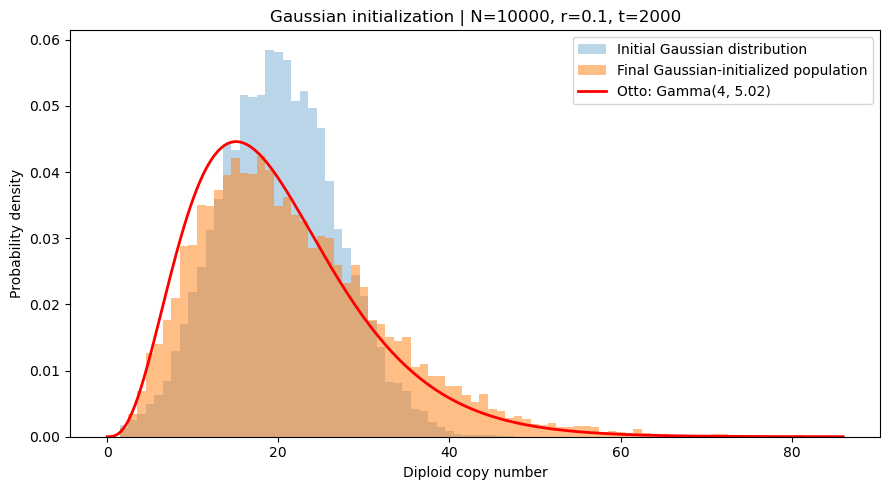

In [49]:
from scipy.stats import gamma

alpha_theory_gaussian = 4
theta_theory_gaussian = (
    initial_mean_dip_gaussian / alpha_theory_gaussian
)

x_gaussian = np.linspace(
    0,
    max(70, final_dip_gaussian.max() + 5),
    500
)

bins_gaussian = np.arange(
    min(initial_dip_gaussian.min(), final_dip_gaussian.min()) - 0.5,
    max(initial_dip_gaussian.max(), final_dip_gaussian.max()) + 1.5,
    1
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    initial_dip_gaussian,
    bins=bins_gaussian,
    density=True,
    alpha=0.3,
    label="Initial Gaussian distribution"
)

ax.hist(
    final_dip_gaussian,
    bins=bins_gaussian,
    density=True,
    alpha=0.5,
    label="Final Gaussian-initialized population"
)

ax.plot(
    x_gaussian,
    gamma.pdf(
        x_gaussian,
        a=alpha_theory_gaussian,
        scale=theta_theory_gaussian
    ),
    "r-",
    linewidth=2,
    label=f"Otto: Gamma(4, {theta_theory_gaussian:.2f})"
)

ax.set_xlabel("Diploid copy number")
ax.set_ylabel("Probability density")
ax.set_title(
    f"Gaussian initialization | N={N_gaussian}, "
    f"r={rec_gaussian}, t={generations_gaussian}"
)

ax.legend()
plt.tight_layout()
plt.show()

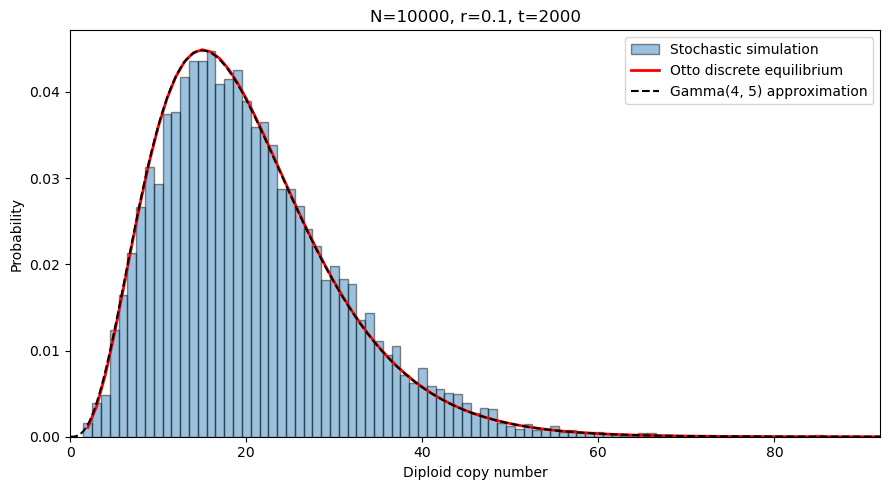

In [36]:
# Theoretical equilibrium
alpha = 4
initial_mean_dip = 2 * init_copies
theta = initial_mean_dip / alpha

# Support for theoretical discrete distribution
K = max(200, int(dip.max()) + 50)
k = np.arange(1, K + 1)

# Otto's haploid equilibrium kernel
p_hap = k * np.exp(-2 * k / init_copies)
p_hap = p_hap / p_hap.sum()

# Convolution gives diploid distribution
p_dip = np.convolve(p_hap, p_hap)

dip_support = np.arange(2, 2 * K + 1)

# Continuous Gamma approximation
x = np.linspace(0, max(70, dip.max() + 5), 500)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    dip,
    bins=np.arange(1.5, max(dip.max(), 70) + 1.5, 1),
    density=True,
    alpha=0.45,
    edgecolor="black",
    label="Stochastic simulation"
)

ax.plot(
    dip_support,
    p_dip,
    "r-",
    linewidth=2,
    label="Otto discrete equilibrium"
)

ax.plot(
    x,
    gamma.pdf(x, a=alpha, scale=theta),
    "k--",
    linewidth=1.5,
    label="Gamma(4, 5) approximation"
)

ax.set_xlim(0, max(70, dip.max() + 5))
ax.set_xlabel("Diploid copy number")
ax.set_ylabel("Probability")
ax.set_title(
    f"N={N}, r={rec}, t={generations}"
)
ax.legend()

plt.tight_layout()
plt.show()

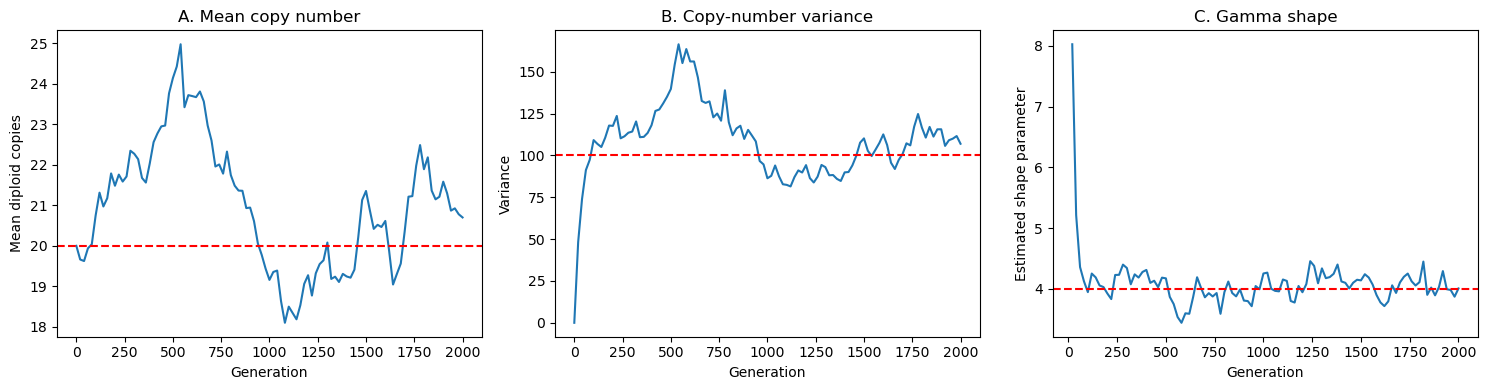

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Mean diploid copy number
axes[0].plot(
    df_history["generation"],
    df_history["mean_dip"]
)
axes[0].axhline(20, color="red", linestyle="--")
axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Mean diploid copies")
axes[0].set_title("A. Mean copy number")

# Variance
axes[1].plot(
    df_history["generation"],
    df_history["var_dip"]
)
axes[1].axhline(100, color="red", linestyle="--")
axes[1].set_xlabel("Generation")
axes[1].set_ylabel("Variance")
axes[1].set_title("B. Copy-number variance")

# Gamma shape estimate
axes[2].plot(
    df_history["generation"],
    df_history["alpha_est"]
)
axes[2].axhline(4, color="red", linestyle="--")
axes[2].set_xlabel("Generation")
axes[2].set_ylabel("Estimated shape parameter")
axes[2].set_title("C. Gamma shape")

plt.tight_layout()
plt.show()

In [39]:
N = 10000
rec = 0.1
generations = 1000
replicates = 100

final_means = []
final_distributions = []
final_alphas = []

for rep in range(replicates):
    rng = np.random.default_rng(rep)

    pop = initialize_population(
        N=N,
        mode="constant",
        init_copies=10,
        rng=rng
    )

    for t in range(generations):
        pop = evolve_fast(pop, rec, rng)

    # Save final diploid copy numbers
    dip = pop.hap_counts.sum(axis=1)

    final_distributions.append(dip.copy())
    final_means.append(dip.mean())

    # Estimate Gamma shape parameter
    final_alphas.append(
        dip.mean()**2 / dip.var()
    )

final_means = np.array(final_means)
final_alphas = np.array(final_alphas)

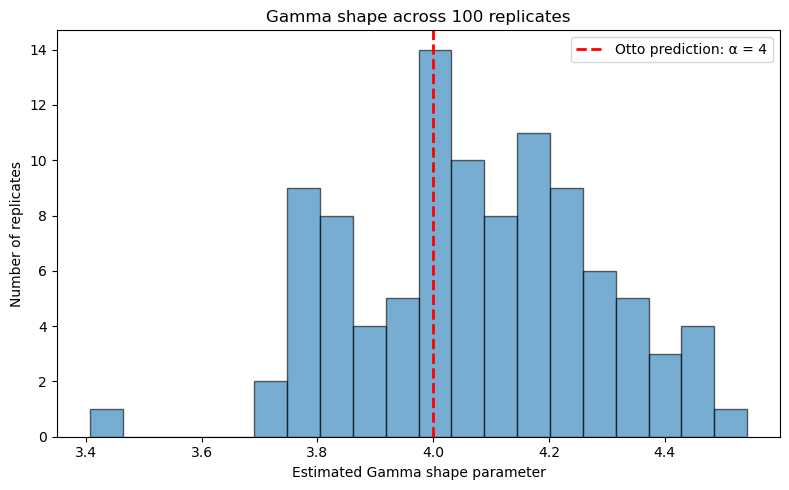

Mean alpha: 4.075531542313295
SD alpha: 0.21023252681014068


In [40]:

plt.figure(figsize=(8, 5))

plt.hist(
    final_alphas,
    bins=20,
    edgecolor="black",
    alpha=0.6
)

plt.axvline(
    4,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Otto prediction: α = 4"
)

plt.xlabel("Estimated Gamma shape parameter")
plt.ylabel("Number of replicates")
plt.title("Gamma shape across 100 replicates")
plt.legend()

plt.tight_layout()
plt.show()

print("Mean alpha:", final_alphas.mean())
print("SD alpha:", final_alphas.std(ddof=1))

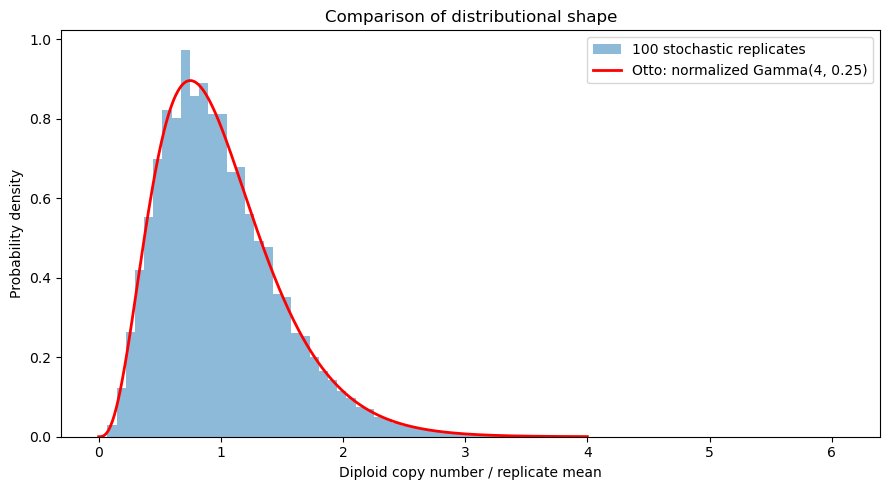

In [41]:


# Normalize each replicate by its own mean
normalized = np.array([
    dip / dip.mean()
    for dip in final_distributions
])

# Equal-weight pooling across replicates
pooled = normalized.flatten()

x = np.linspace(0, 4, 500)

plt.figure(figsize=(9, 5))

plt.hist(
    pooled,
    bins=80,
    density=True,
    alpha=0.5,
    label="100 stochastic replicates"
)

plt.plot(
    x,
    gamma.pdf(x, a=4, scale=0.25),
    "r-",
    linewidth=2,
    label="Otto: normalized Gamma(4, 0.25)"
)

plt.xlabel("Diploid copy number / replicate mean")
plt.ylabel("Probability density")
plt.title("Comparison of distributional shape")
plt.legend()

plt.tight_layout()
plt.show()

In [50]:
# ==========================================
# V0.3 — 100 Gaussian replicates
# ==========================================

N_gaussian_reps = 10000
rec_gaussian_reps = 0.1
generations_gaussian_reps = 2000
replicates_gaussian = 100

init_mean_gaussian_reps = 10
init_sd_gaussian_reps = 2

# Store results
initial_means_gaussian_reps = []
final_means_gaussian_reps = []
final_alphas_gaussian_reps = []
final_distributions_gaussian_reps = []

for rep in range(replicates_gaussian):

    rng_rep = np.random.default_rng(1000 + rep)

    # Gaussian initialization
    pop_rep = initialize_population(
        N=N_gaussian_reps,
        mode="gaussian",
        mean=init_mean_gaussian_reps,
        sd=init_sd_gaussian_reps,
        rng=rng_rep
    )

    initial_dip_rep = pop_rep.hap_counts.sum(axis=1)
    initial_means_gaussian_reps.append(initial_dip_rep.mean())

    # Evolution
    for t in range(generations_gaussian_reps):
        pop_rep = evolve_fast(
            pop_rep,
            rec_gaussian_reps,
            rng_rep
        )

    # Final diploid copy numbers
    final_dip_rep = pop_rep.hap_counts.sum(axis=1)

    final_distributions_gaussian_reps.append(
        final_dip_rep.copy()
    )

    final_means_gaussian_reps.append(
        final_dip_rep.mean()
    )

    final_alphas_gaussian_reps.append(
        final_dip_rep.mean()**2 / final_dip_rep.var()
    )

# Convert results to arrays
initial_means_gaussian_reps = np.array(
    initial_means_gaussian_reps
)

final_means_gaussian_reps = np.array(
    final_means_gaussian_reps
)

final_alphas_gaussian_reps = np.array(
    final_alphas_gaussian_reps
)

final_distributions_gaussian_reps = np.array(
    final_distributions_gaussian_reps
)

# Summary
print("Gaussian initialization — 100 replicates")
print("Mean initial diploid copies:",
      initial_means_gaussian_reps.mean())
print("Mean final diploid copies:",
      final_means_gaussian_reps.mean())
print("SD of final means:",
      final_means_gaussian_reps.std(ddof=1))
print("Mean estimated alpha:",
      final_alphas_gaussian_reps.mean())
print("SD of alpha:",
      final_alphas_gaussian_reps.std(ddof=1))

Gaussian initialization — 100 replicates
Mean initial diploid copies: 20.003280000000004
Mean final diploid copies: 19.923029
SD of final means: 4.566851502392877
Mean estimated alpha: 4.063808734297587
SD of alpha: 0.18859911674428642


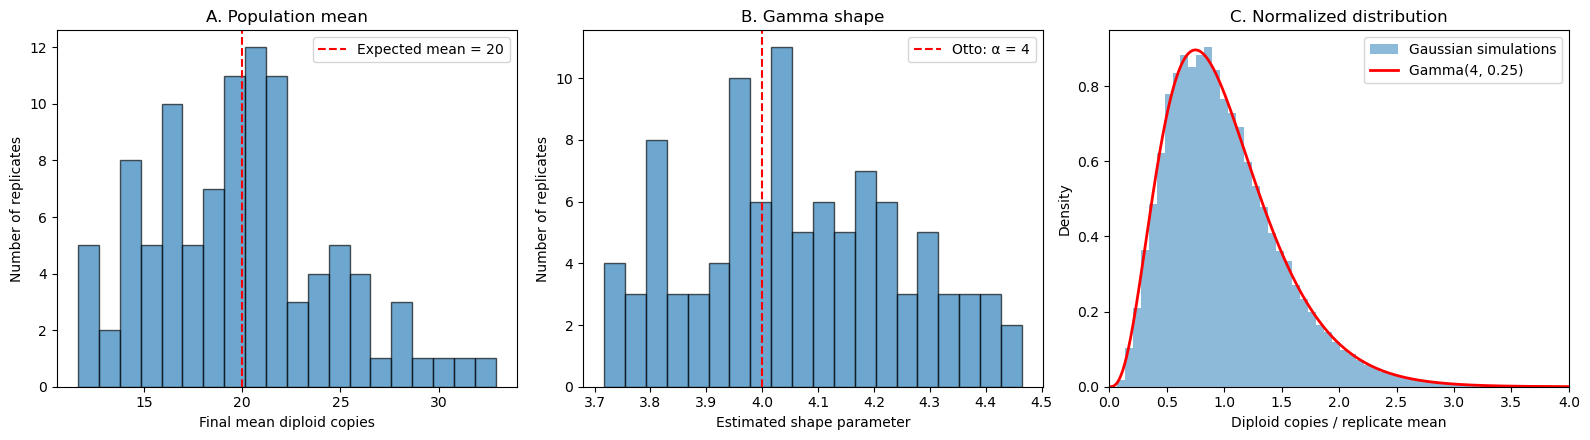

In [51]:
from scipy.stats import gamma

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# A. Final means across replicates
axes[0].hist(
    final_means_gaussian_reps,
    bins=20,
    edgecolor="black",
    alpha=0.65
)
axes[0].axvline(
    20, color="red", linestyle="--",
    label="Expected mean = 20"
)
axes[0].set_xlabel("Final mean diploid copies")
axes[0].set_ylabel("Number of replicates")
axes[0].set_title("A. Population mean")
axes[0].legend()

# B. Estimated Gamma shape
axes[1].hist(
    final_alphas_gaussian_reps,
    bins=20,
    edgecolor="black",
    alpha=0.65
)
axes[1].axvline(
    4, color="red", linestyle="--",
    label="Otto: α = 4"
)
axes[1].set_xlabel("Estimated shape parameter")
axes[1].set_ylabel("Number of replicates")
axes[1].set_title("B. Gamma shape")
axes[1].legend()

# C. Normalized final distributions
normalized_gaussian_reps = (
    final_distributions_gaussian_reps
    / final_means_gaussian_reps[:, None]
)

x = np.linspace(0, 4, 500)

axes[2].hist(
    normalized_gaussian_reps.flatten(),
    bins=80,
    density=True,
    alpha=0.5,
    label="Gaussian simulations"
)

axes[2].plot(
    x,
    gamma.pdf(x, a=4, scale=0.25),
    "r-",
    linewidth=2,
    label="Gamma(4, 0.25)"
)

axes[2].set_xlim(0, 4)
axes[2].set_xlabel("Diploid copies / replicate mean")
axes[2].set_ylabel("Density")
axes[2].set_title("C. Normalized distribution")
axes[2].legend()

plt.tight_layout()
plt.show()